# Lab: Comparing tSNE and UMAP Dimension Reduction Models — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/01-machine-learning-with-python/notebooks/lab-comparing-tsne-and-umap-dimension-reduction-models.ipynb) · [Course notes](../../../courses/01-machine-learning-with-python/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# Lab: Comparing tSNE and UMAP Dimension Reduction Models
Estimated time needed: **30** minutes
    

## Objectives

After completing this lab you will be able to:

* Apply tSNE and UMAP to feature space dimensionality reduction problems
* Use PCA as a baseline comparison for evaluating tSNE and UMAP results



## Introduction

In this lab, you will explore how to implement two advanced dimensionality reduction algorithms, tSNE and UMAP, on synthetic data.
You'll compare the results to the same dimension reduction using PCA.

- You'll start by generating a synthetic dataset of blobs in a 3D feature space and visually explore the data in an interactive 3D plot. 
- Then, you'll use the three algorithms to project the blobs into two dimensions.
  
For illustrative purposes, you'll color the blobs so we can see what effect the dimension reduction algorithms have on them: how well they preserve structure, such as the separation between blobs and their relative density.


### Import the required libraries


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
import umap.umap_ as UMAP
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import plotly.express as px
from sklearn.datasets import make_blobs

Matplotlib is building the font cache; this may take a moment.


<repository>/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Generate synthetic data with four clusters in a 3D space


In [3]:
centers = [[2, -6, -6], [-1, 9, 4], [-8, 7, 2], [4, 7, 9]]
cluster_std = [1, 1, 2, 3.5]
X, labels_ = make_blobs(n_samples=500, centers=centers, n_features=3, cluster_std=cluster_std, random_state=42)

### Display the data in an interactive Plotly 3D scatter plot


In [4]:
df = pd.DataFrame(X, columns=['X', 'Y', 'Z'])
fig = px.scatter_3d(df, x='X', y='Y', z='Z', color=labels_.astype(str), opacity=0.7, color_discrete_sequence=px.colors.qualitative.G10, title='3D Scatter Plot of Four Blobs')
fig.update_traces(marker=dict(size=5, line=dict(width=1, color='black')), showlegend=False)
fig.update_layout(coloraxis_showscale=False, width=1000, height=800)
fig.show()

### Interact with the plot
Go ahead and click on the icons at the top right of the plot to select zoom, rotate, and pan modes.

Then use your mouse to interact with the plot. 

This is a great way to inspect 3D data as it's difficult to learn much from a static 3D plot.
### Exercise 1. What can you say about the four blobs?


<details><summary>Click here for some observations </summary>

- The blobs have varying densities.
- One blob is distinct from the others.
- The two largest blobs are distinct from each other, but both have a bit of overlap with the other blob between them.

</details>


### Exercise 2. Standardize the data to prepare it for the three projection methods.


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

<details><summary>Click here for the solution</summary>

```python
# Standardize the data 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
```


### Apply t-SNE to reduce the dimensionality to 2D
You'll set the perplexity to the default value of 30 here. The results vary quite a bit if you change the perplexity, so go ahead and experiment.


In [6]:
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

<repository>/.venv/lib/python3.11/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning:

divide by zero encountered in matmul

<repository>/.venv/lib/python3.11/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning:

overflow encountered in matmul

<repository>/.venv/lib/python3.11/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning:

invalid value encountered in matmul

<repository>/.venv/lib/python3.11/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning:

divide by zero encountered in matmul

<repository>/.venv/lib/python3.11/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning:

overflow encountered in matmul

<repository>/.venv/lib/python3.11/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning:

invalid value encountered in matmul



### Let's plot the 2D t-SNE result


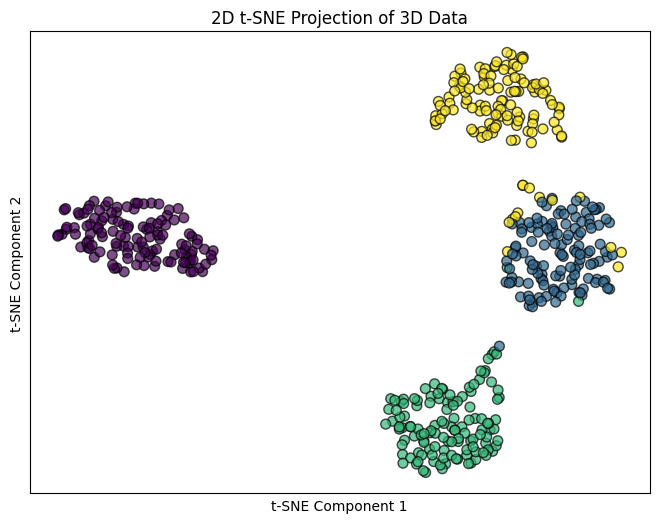

In [7]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)
ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels_, cmap='viridis', s=50, alpha=0.7, edgecolor='k')
ax.set_title('2D t-SNE Projection of 3D Data')
ax.set_xlabel('t-SNE Component 1')
ax.set_ylabel('t-SNE Component 2')
ax.set_xticks([])
ax.set_yticks([])
plt.show()

### Exercise 3. What can you say about this t-SNE result?


<details><summary>Click here for some observations</summary>

- t-SNE projected the data into four distinct clusters, although the original data had some overlap between a few clusters.
- You can see that some of the points ended up in the "wrong" cluster, although to be fair, t-SNE has no knowledge of which clusters the points actually belong to. 
- All the clusters have similar densities.
- Two of the blobs are distinct from each other but "gave up" some of their points to the blob they originally had overlapped with.
- A "perfect" result would not completely separate the overlaps between blobs.
- Notice that the distance between the blobs is consistent with the degree to which they were originally separated.
</details>


## Compare UMAP and PCA dimensionality reduction to two dimensions


<repository>/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



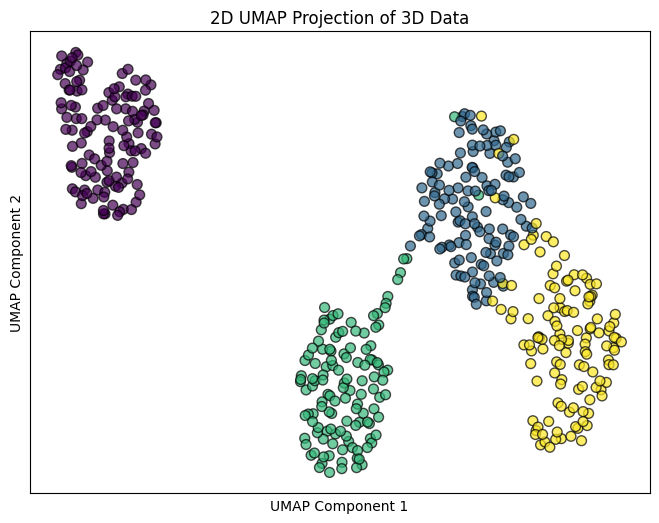

In [8]:
umap_model = UMAP.UMAP(n_components=2, random_state=42, min_dist=0.5, spread=1, n_jobs=1)
X_umap = umap_model.fit_transform(X_scaled)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)
ax.scatter(X_umap[:, 0], X_umap[:, 1], c=labels_, cmap='viridis', s=50, alpha=0.7, edgecolor='k')
ax.set_title('2D UMAP Projection of 3D Data')
ax.set_xlabel('UMAP Component 1')
ax.set_ylabel('UMAP Component 2')
ax.set_xticks([])
ax.set_yticks([])
plt.show()

### Exercise 4. What can you say about this UMAP result?


<details><summary>Click here for some observations</summary>

- UMAP correctly projected the data into four partially distinct clusters, with one cluster completely distinct from the others.
- Unlike t-SNE, it has preserved the connectedness that the original data had with the partially overlapping clusters.
- You can see that, like t-SNE, some of the points ended up in the "wrong" cluster.
- Again, like t-SNE, all the clusters have similar densities.
- A "perfect" result would not completely separate the overlaps between blobs, because they actually do overlap in the original feature space.
- The distance between the clusters is again consistent with the degree to which they were originally separated.
</details>



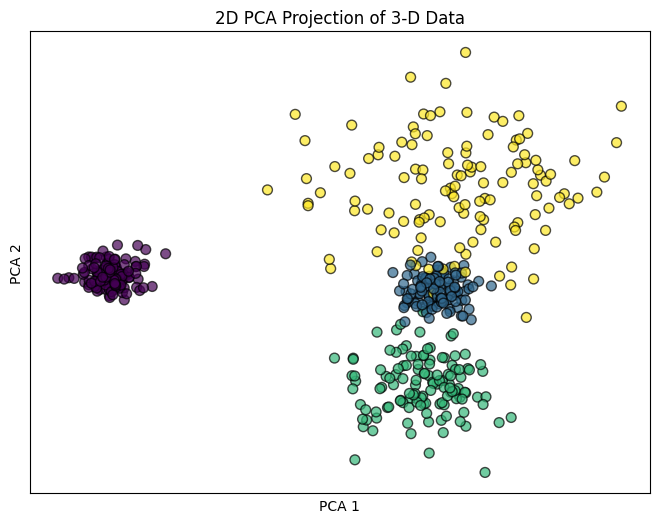

In [9]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
fig = plt.figure(figsize=(8, 6))
ax2 = fig.add_subplot(111)
scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_, cmap='viridis', s=50, alpha=0.7, edgecolor='k')
ax2.set_title('2D PCA Projection of 3-D Data')
ax2.set_xlabel('PCA 1')
ax2.set_ylabel('PCA 2')
ax2.set_xticks([])
ax2.set_yticks([])
plt.show()

### Exercise 5. What can you say about this PCA result?


<details><summary>Click here for some observations</summary>

- PCA faithfully preserved the relative blob densities.
- PCA also preserved the relative separation between blobs.
- The distance between the clusters is very consistent with the degree to which they were originally separated.
- PCA and t-SNE took very little time to complete compared to UMAP.
- IMNSHO, PCA outperformed both t-SNE and UMAP in this experiment.
This points to a common tendency to want to implement more advanced algorithms.
The default result is not always an improvement over the simpler established methods.

</details>




### Congratulations! You're ready to move on to your next lesson!


## Author

<a href="https://www.linkedin.com/in/jpgrossman/" target="_blank">Jeff Grossman</a>

### Other Contributors
<a href="https://www.linkedin.com/in/abhishek-gagneja-23051987/" target="_blank">Abhishek Gagneja</a>



<!-- ## Changelog

| Date | Version | Changed by | Change Description |
|:------------|:------|:------------------|:---------------------------------------|
| 2024-11-05 | 1.0  | Jeff Grossman    | Create content | -->



## <h3 align="center"> © IBM Corporation. All rights reserved. <h3/>
